Color channels:  3
Filter size:  3 3
Total number of filters:  64


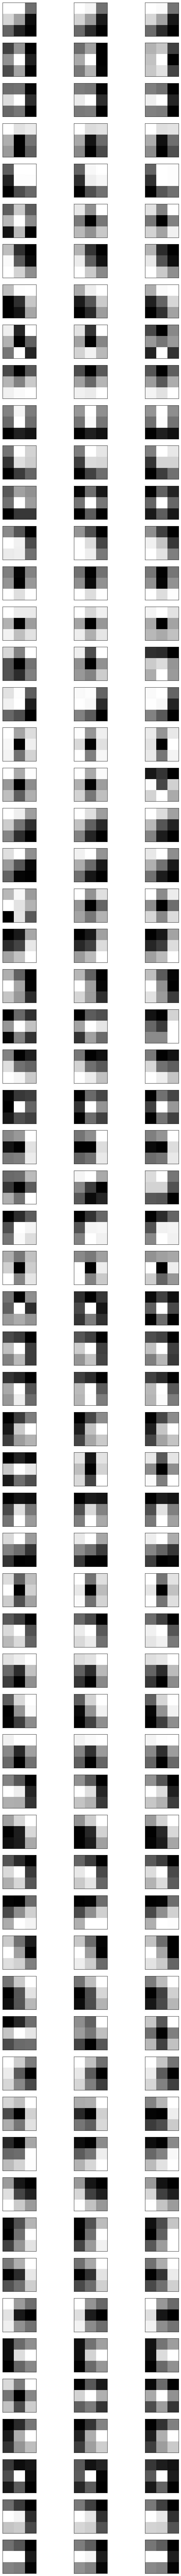

In [1]:
from keras.applications.vgg19 import VGG19
from matplotlib import pyplot

model = VGG19()

# Retrieve weights from the first hidden layer.
n = 1
filters, biases = model.layers[n].get_weights()
s = filters.shape
print("Color channels: ", s[2])
print("Filter size: ", s[0], s[1])
print("Total number of filters: ", s[3])

# Normalize filter values to 0-1 so we can visualize them.
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

# Display every filter in the selected layer.
n_filters, ix = s[3], 1
channels_to_show = min(3, s[2])
pyplot.figure(figsize=(10, max(10, n_filters * 2)))
for i in range(n_filters):
    f = filters[:, :, :, i]
    for j in range(channels_to_show):
        ax = pyplot.subplot(n_filters, channels_to_show, ix)
        ax.set_xticks([])
        ax.set_yticks([])
        pyplot.imshow(f[:, :, j], cmap='gray')
        ix += 1
pyplot.show()

## Results

Using `n_filters, ix = s[3], 1` displays all 64 filters in the selected VGG19 convolutional layer. Each filter is shown across three input channels, producing a tall grid of 192 small grayscale images. The complete view shows that the layer contains many different edge, contrast, and texture detectors rather than only the four examples shown previously.